# Assignment 1

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [4]:
import requests
from bs4 import BeautifulSoup

def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.
    """
    headers = {
        "User-Agent": "Mozilla/5.0"
    }

    response = requests.get(url, headers=headers, timeout=20)
    response.raise_for_status()

    root = BeautifulSoup(response.content, "html.parser")

    # Remove scripts, styles and other non-visible content
    for element in root(["script", "style", "noscript"]):
        element.decompose()

    return root.get_text(separator=" ", strip=True)


print(parse_web_page("https://fmi.chnu.edu.ua/")[:255])
print(parse_web_page("https://en.wikipedia.org/wiki/Web_scraping")[:255])

Головна - Факультет математики та інформатики Перейти до основного вмісту clg-math@chnu.edu.ua 58012, Україна, м. Чернівці, вул. Університетська, 28 Новини Всі Загальні Оголошення Події Студенту Викладачу Вітання Діяльність Наукова Конференції Семінари Ас
Web scraping - Wikipedia Jump to content Main menu Main menu move to sidebar hide Navigation Main page Contents Current events Random article About Wikipedia Contact us Contribute Help Learn to edit Community portal Recent changes Upload file Special page


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [6]:
import requests
import json

def parse_api(api_url):

    response = requests.get(api_url, timeout=20)
    response.raise_for_status()

    data = response.json()

    with open("result.json", "w", encoding="utf-8") as file:
        json.dump(data, file, ensure_ascii=False, indent=4)


parse_api("https://api.github.com/")


## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [15]:
import json
def parse_json(date):
    with open("resources/weather.json", "r", encoding="utf-8") as file:
        data = json.load(file)

    result = []

    for item in data["daily"]:
        if item["date"] == date:
            result.append(item)

    return result

target_date = '2024-08-19'
print(parse_json(target_date))

[{'date': '2024-08-19', 'max_temperature': 30.0, 'min_temperature': 21.0, 'precipitation': 5.0, 'wind_speed': 10.0, 'humidity': 70, 'weather_description': 'Light rain'}]


In [11]:
!git clone -b main https://github.com/skhbrsz/ida-labs.git

Cloning into 'ida-labs'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 53 (delta 13), reused 48 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 3.34 MiB | 10.34 MiB/s, done.
Resolving deltas: 100% (13/13), done.


In [12]:
%cd ida-labs

/content/ida-labs


In [13]:
!ls resources

bitcoin.csv		    data.json			ratings.csv
cars_clus.csv		    drug.csv			Salary_dataset.csv
cell_samples.csv	    example.csv			sales.csv
china_gdp.csv		    heart.csv			telecom_cus.csv
churn_Data.csv		    ice_cream_selling_data.csv	weather.csv
CO2_emission.csv	    movies.csv			weather.json
cust_segmentation_Data.csv  o2Saturation.csv
data.csv		    powerconsumption.csv


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [18]:
import pandas as pd
def parse_csv(date):

    df = pd.read_csv("resources/weather.csv")
    result = df[df["CET"] == date]
    return result.values.tolist()

target_date = '1997-5-22'
print(parse_csv(target_date))

[['1997-5-22', 25.0, 18.0, 10.0, 11.0, 8.0, 6.0, 88.0, 54.0, 34.0, 1017, 1015, 1012, 10.0, 10.0, 10.0, 11, 3, nan, 0.0, 3.0, nan, 277]]


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

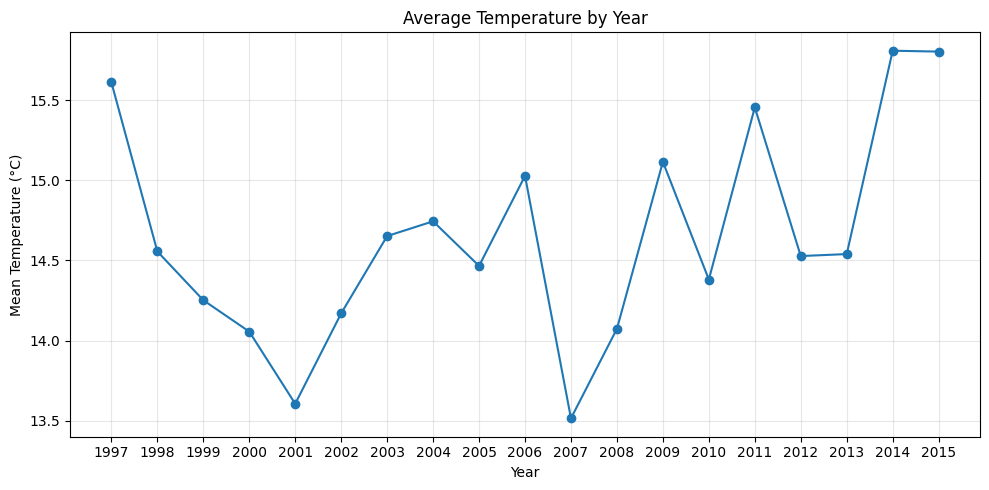

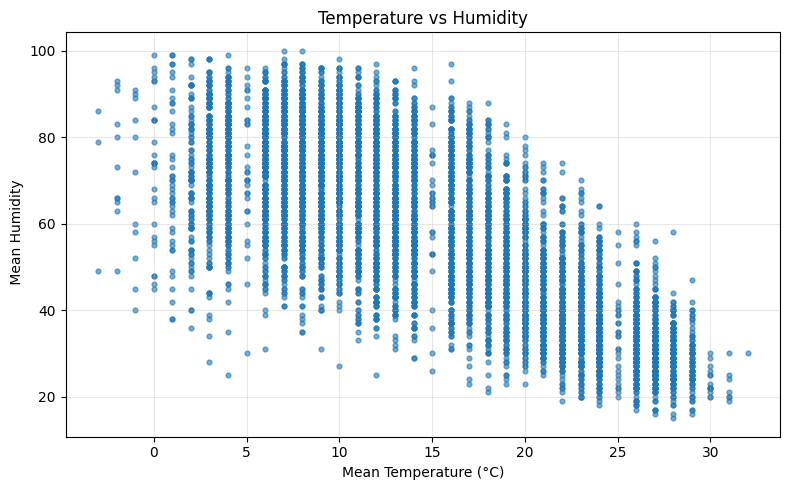

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_csv("resources/weather.csv")

df["CET"] = pd.to_datetime(df["CET"], errors="coerce")
df["Mean TemperatureC"] = pd.to_numeric(
    df["Mean TemperatureC"], errors="coerce"
)

humidity_columns = [c for c in df.columns if "Humidity" in c]

if not humidity_columns:
    raise ValueError("У CSV не знайдено стовпця вологості.")

humidity_column = next(
    (c for c in humidity_columns if "Mean" in c),
    humidity_columns[0]
)

df[humidity_column] = pd.to_numeric(
    df[humidity_column], errors="coerce"
)

os.makedirs("resources/plots", exist_ok=True)

# Лінійна діаграма: середня температура за роками
df["Year"] = df["CET"].dt.year

yearly_temperature = (
    df.groupby("Year")["Mean TemperatureC"].mean().dropna()
)

plt.figure(figsize=(10, 5))
plt.plot(yearly_temperature.index, yearly_temperature.values, marker="o")
plt.title("Average Temperature by Year")
plt.xlabel("Year")
plt.ylabel("Mean Temperature (°C)")
plt.xticks(yearly_temperature.index.astype(int))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("resources/plots/temperature_by_year.png", dpi=150)
plt.show()
plt.close()

# Точкова діаграма: температура та вологість
data = df.dropna(
    subset=["Mean TemperatureC", humidity_column]
)

plt.figure(figsize=(8, 5))
plt.scatter(
    data["Mean TemperatureC"],
    data[humidity_column],
    s=12,
    alpha=0.6
)
plt.title("Temperature vs Humidity")
plt.xlabel("Mean Temperature (°C)")
plt.ylabel(humidity_column)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("resources/plots/temperature_vs_humidity.png", dpi=150)
plt.show()
plt.close()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

In [35]:
pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

In [39]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Папка для результатів
os.makedirs("results", exist_ok=True)

def load_dataset(url, csv_file):

    dataset_path = kagglehub.dataset_download(url)
    csv_paths = glob.glob(
        os.path.join(dataset_path, "**", "*.csv"),
        recursive=True
    )

    matching_paths = [
        path for path in csv_paths
        if os.path.basename(path).lower() == csv_file.lower()
    ]

    if matching_paths:
        file_path = matching_paths[0]
    elif len(csv_paths) == 1:
        file_path = csv_paths[0]
        print("Увага: використано єдиний доступний CSV:", file_path)
    else:
        print("Доступні CSV-файли:")
        for path in csv_paths:
            print(path)
        raise FileNotFoundError(
            f"Не знайдено {csv_file}. Перевір назву файлу."
        )

    df = pd.read_csv(file_path)

    print("\nДатасет завантажено.")
    print("Розмір:", df.shape)
    print("\nПерші п'ять рядків:")
    print(df.head())
    print("\nТипи даних:")
    print(df.dtypes)

    return df

#  Аналіз пропущених значень

def analyze_missing_data(df):
    missing = df.isna().sum()

    print("\nПропущені значення:")
    print(missing[missing > 0])

    missing.to_csv("results/missing_values.csv")

    plt.figure(figsize=(10, 5))
    missing[missing > 0].sort_values().plot(
        kind="barh"
    )
    plt.title("Кількість пропущених значень")
    plt.xlabel("Кількість пропусків")
    plt.ylabel("Стовпці")
    plt.tight_layout()
    plt.savefig("results/missing_values.png", dpi=150)
    plt.close()

#  Заповнення пропусків


def impute_data(df):
    """
    Порівнює Mean, Median, Mode та KNN.
    Числові стовпці обробляються окремо від категоріальних.
    """
    numeric_cols = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_cols = df.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    results = {}

    # Метод 1: Mean
    mean_df = df.copy()
    if numeric_cols:
        mean_imputer = SimpleImputer(strategy="mean")
        mean_df[numeric_cols] = mean_imputer.fit_transform(
            mean_df[numeric_cols]
        )
    if categorical_cols:
        mode_imputer = SimpleImputer(strategy="most_frequent")
        mean_df[categorical_cols] = mode_imputer.fit_transform(
            mean_df[categorical_cols]
        )
    results["Mean"] = mean_df

    # Метод 2: Median
    median_df = df.copy()
    if numeric_cols:
        median_imputer = SimpleImputer(strategy="median")
        median_df[numeric_cols] = median_imputer.fit_transform(
            median_df[numeric_cols]
        )
    if categorical_cols:
        mode_imputer = SimpleImputer(strategy="most_frequent")
        median_df[categorical_cols] = mode_imputer.fit_transform(
            median_df[categorical_cols]
        )
    results["Median"] = median_df

    # Метод 3: Mode
    mode_df = df.copy()
    if numeric_cols:
        mode_imputer = SimpleImputer(strategy="most_frequent")
        mode_df[numeric_cols] = mode_imputer.fit_transform(
            mode_df[numeric_cols]
        )
    if categorical_cols:
        mode_imputer = SimpleImputer(strategy="most_frequent")
        mode_df[categorical_cols] = mode_imputer.fit_transform(
            mode_df[categorical_cols]
        )
    results["Mode"] = mode_df

    # Метод 4: KNN для числових ознак.
    # Категоріальні ознаки заповнюємо модою.
    knn_df = df.copy()

    if numeric_cols:
        # Виключаємо стовпці, де всі значення відсутні
        valid_numeric = [
            col for col in numeric_cols
            if df[col].notna().any()
        ]
        all_missing_numeric = [
            col for col in numeric_cols
            if df[col].isna().all()
        ]

        if valid_numeric:
            knn_imputer = KNNImputer(n_neighbors=5)
            knn_values = knn_imputer.fit_transform(
                df[valid_numeric]
            )

            knn_df[valid_numeric] = knn_values

        # Якщо стовпець повністю порожній, KNN не може
        # відновити його без додаткової інформації.
        for col in all_missing_numeric:
            knn_df[col] = 0

    if categorical_cols:
        mode_imputer = SimpleImputer(strategy="most_frequent")
        knn_df[categorical_cols] = mode_imputer.fit_transform(
            knn_df[categorical_cols]
        )

    results["KNN"] = knn_df

    # Звітуємо про результат кожного методу
    for name, result in results.items():
        print(
            f"{name}: залишилося пропусків = "
            f"{result.isna().sum().sum()}"
        )
        result.to_csv(
            f"results/imputed_{name.lower()}.csv",
            index=False
        )

    # Попередній вибір медіани як стійкого базового методу.
    # Нижче його можна замінити за результатами порівняння.
    selected_df = results["Median"].copy()

    # Категоріальні пропуски заповнюємо модою.
    if categorical_cols:
        selected_df[categorical_cols] = results["Mode"][
            categorical_cols
        ]

    selected_df.to_csv(
        "results/imputed_selected.csv",
        index=False
    )

    return selected_df


#  Порівняння методів нормалізації

def normalize_data(df):
    """
    Створює версії з Min-Max, Z-score та Robust Scaling.
    Порівнює викиди та обирає підхід для числових даних.
    """
    numeric_cols = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    if not numeric_cols:
        print("Немає числових стовпців для нормалізації.")
        return df.copy()

    numeric_data = df[numeric_cols].copy()

    # Видаляємо константні ознаки з набору для масштабування:
    # вони не несуть інформації про розподіл.
    constant_cols = [
        col for col in numeric_cols
        if numeric_data[col].nunique() <= 1
    ]
    scale_cols = [
        col for col in numeric_cols
        if col not in constant_cols
    ]

    scaled_results = {}

    scalers = {
        "minmax": MinMaxScaler(),
        "zscore": StandardScaler(),
        "robust": RobustScaler()
    }

    for name, scaler in scalers.items():
        scaled_df = df.copy()

        if scale_cols:
            scaled_df[scale_cols] = scaler.fit_transform(
                numeric_data[scale_cols]
            )

        scaled_results[name] = scaled_df

        scaled_df.to_csv(
            f"results/normalized_{name}.csv",
            index=False
        )

    # Виявлення викидів за правилом 1.5 * IQR
    outlier_counts = {}

    for col in scale_cols:
        q1 = numeric_data[col].quantile(0.25)
        q3 = numeric_data[col].quantile(0.75)
        iqr = q3 - q1

        if iqr == 0:
            outlier_counts[col] = 0
        else:
            outliers = (
                (numeric_data[col] < q1 - 1.5 * iqr)
                | (numeric_data[col] > q3 + 1.5 * iqr)
            )
            outlier_counts[col] = int(outliers.sum())

    total_outliers = sum(outlier_counts.values())
    total_values = max(len(df) * len(scale_cols), 1)
    outlier_share = total_outliers / total_values

    # Правило вибору для попереднього аналізу:
    # багато викидів -> Robust;
    # інакше -> Z-score.
    # Min-Max також зберігається для порівняння.
    if outlier_share > 0.01:
        selected_method = "robust"
    else:
        selected_method = "zscore"

    print("\nВикиди за правилом 1.5 * IQR:")
    print(outlier_counts)
    print("Частка викидів:", round(outlier_share * 100, 2), "%")
    print("Попередньо обраний метод:", selected_method)

    # Зберігаємо обраний результат
    final_df = scaled_results[selected_method].copy()
    final_df.to_csv("results/normalized_selected.csv", index=False)

    return final_df


# Візуалізація даних

def visualize_data(df):
    numeric_cols = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    if not numeric_cols:
        print("Немає числових даних для графіків.")
        return

    # Графік розподілу першої числової ознаки
    col = numeric_cols[0]

    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True)
    plt.title(f"Розподіл ознаки: {col}")
    plt.xlabel(col)
    plt.ylabel("Частота")
    plt.tight_layout()
    plt.savefig("results/distribution.png", dpi=150)
    plt.close()

    # Boxplot числових ознак
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df[numeric_cols])
    plt.title("Boxplot числових ознак")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig("results/boxplot.png", dpi=150)
    plt.close()

    # Кореляційна матриця
    if len(numeric_cols) >= 2:
        plt.figure(figsize=(10, 7))
        sns.heatmap(
            df[numeric_cols].corr(),
            annot=True,
            cmap="coolwarm",
            fmt=".2f"
        )
        plt.title("Кореляційна матриця")
        plt.tight_layout()
        plt.savefig("results/correlation.png", dpi=150)
        plt.close()

    print("\nГрафіки збережено в папці results.")

#  Запуск усіх етапів
if __name__ == "__main__":
    df = load_dataset(
        "ilayaraja07/data-cleaning-feature-imputation",
        "Students_Performance_knn.csv"
    )

    analyze_missing_data(df)

    df_imputed = impute_data(df)

    df_normalized = normalize_data(df_imputed)

    visualize_data(df_imputed)


    print("\nОбробку завершено.")
    print("Початковий розмір:", df.shape)
    print("Розмір після обробки:", df_normalized.shape)
    print(
        "Залишилося пропусків:",
        df_normalized.isna().sum().sum()
    )


Using Colab cache for faster access to the 'data-cleaning-feature-imputation' dataset.

Датасет завантажено.
Розмір: (1000, 8)

Перші п'ять рядків:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Типи даних